# SIL765 Assignment 3 - Network Traffic Analysis

**Course:** Network Systems and Security  
**Date:** 30 March 2026

This notebook analyses ~2 million network flow records from 6 IDS/firewall CSV logs.
It covers:
1. Basic Network Traffic Statistics
2. Traffic Estimation Using Sublinear Space (HyperLogLog, Count-Min Sketch, Bloom Filter)
3. Advanced Anomaly Detection
4. Deep Security Threat Analysis

## Phase 0 - Setup & Data Loading

In [1]:
# uncomment if packages are missing:
# !pip install pandas numpy matplotlib seaborn bitarray

import os, re, math, hashlib, warnings, base64
from collections import defaultdict, Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')

DATA_DIR    = Path(__file__).parent / 'logs' if '__file__' in dir() else Path('logs')
FIGURES_DIR = Path('outputs/figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
CSV_FILES = sorted(DATA_DIR.glob('network_analysis_data*.csv'))
print(f'Found {len(CSV_FILES)} CSV files:')
for f in CSV_FILES:
    print(f'  {f.name}  ({f.stat().st_size / 1e6:.1f} MB)')

Found 6 CSV files:
  network_analysis_data1.csv  (81.5 MB)
  network_analysis_data2.csv  (40.3 MB)
  network_analysis_data3.csv  (77.5 MB)
  network_analysis_data4.csv  (349.0 MB)
  network_analysis_data5.csv  (631.8 MB)
  network_analysis_data6.csv  (408.8 MB)


In [2]:
# load in chunks - full dataset ~1.5 GB, skip columns we don't need
NEEDED_COLS = [
    'source', 'destination', 'sourcePort', 'destinationPort',
    'protocolName', 'appName',
    'totalSourceBytes', 'totalDestinationBytes',
    'totalSourcePackets', 'totalDestinationPackets',
    'startDateTime', 'stopDateTime',
    'sourceTCPFlagsDescription', 'destinationTCPFlagsDescription',
    'sourcePayloadAsUTF', 'destinationPayloadAsUTF',
    'direction', 'Label'
]

CHUNK_SIZE = 100_000
chunks = []

for csv_file in CSV_FILES:
    print(f'Loading {csv_file.name} ...', end=' ')
    file_chunks = []
    for chunk in pd.read_csv(csv_file, chunksize=CHUNK_SIZE,
                              usecols=NEEDED_COLS,
                              low_memory=False):
        file_chunks.append(chunk)
    file_df = pd.concat(file_chunks, ignore_index=True)
    print(f'{len(file_df):,} rows')
    chunks.append(file_df)

df = pd.concat(chunks, ignore_index=True)
print(f'\nTotal rows loaded: {len(df):,}')
print(f'Columns: {list(df.columns)}')

Loading network_analysis_data1.csv ... 171,380 rows
Loading network_analysis_data2.csv ... 133,193 rows
Loading network_analysis_data3.csv ... 275,528 rows
Loading network_analysis_data4.csv ... 397,595 rows
Loading network_analysis_data5.csv ... 571,698 rows
Loading network_analysis_data6.csv ... 522,263 rows

Total rows loaded: 2,071,657
Columns: ['appName', 'totalSourceBytes', 'totalDestinationBytes', 'totalDestinationPackets', 'totalSourcePackets', 'sourcePayloadAsUTF', 'destinationPayloadAsUTF', 'direction', 'sourceTCPFlagsDescription', 'destinationTCPFlagsDescription', 'source', 'protocolName', 'sourcePort', 'destination', 'destinationPort', 'startDateTime', 'stopDateTime', 'Label']


In [3]:
df['startDateTime'] = pd.to_datetime(df['startDateTime'], errors='coerce')
df['stopDateTime']  = pd.to_datetime(df['stopDateTime'],  errors='coerce')

df['totalBytes']   = df['totalSourceBytes'].fillna(0) + df['totalDestinationBytes'].fillna(0)
df['totalPackets'] = df['totalSourcePackets'].fillna(0) + df['totalDestinationPackets'].fillna(0)

# clip negatives that show up when stopDateTime < startDateTime (data quirk)
df['duration_s'] = (df['stopDateTime'] - df['startDateTime']).dt.total_seconds()
df['duration_s'] = df['duration_s'].clip(lower=0)

# NaN where packet count is zero to avoid div-by-zero
df['avg_pkt_bytes'] = np.where(
    df['totalPackets'] > 0,
    df['totalBytes'] / df['totalPackets'],
    np.nan
)

print('Derived columns computed.')
print(df[['totalBytes','totalPackets','duration_s','avg_pkt_bytes']].describe())

Derived columns computed.
         totalBytes  totalPackets    duration_s  avg_pkt_bytes
count  2.071657e+06  2.071657e+06  2.071657e+06   2.071657e+06
mean   3.695006e+04  5.014087e+01  4.898693e+01   3.157890e+02
std    1.446485e+06  1.632601e+03  6.197693e+02   2.660748e+02
min    6.400000e+01  1.000000e+00  0.000000e+00   6.400000e+01
25%    5.350000e+02  4.000000e+00  0.000000e+00   1.190000e+02
50%    1.635000e+03  1.000000e+01  0.000000e+00   1.953846e+02
75%    8.236000e+03  2.100000e+01  0.000000e+00   4.580580e+02
max    1.281862e+09  1.306305e+06  4.914000e+04   2.149500e+03


---
## Section 1 - Basic Network Traffic Statistics

In [4]:
# 1.1 total flows
total_flows = len(df)
print(f'Total network flows: {total_flows:,}')

Total network flows: 2,071,657


Top 5 protocols:
protocolName
tcp_ip     1644056
udp_ip      419246
icmp_ip       8211
igmp            77
ip              66


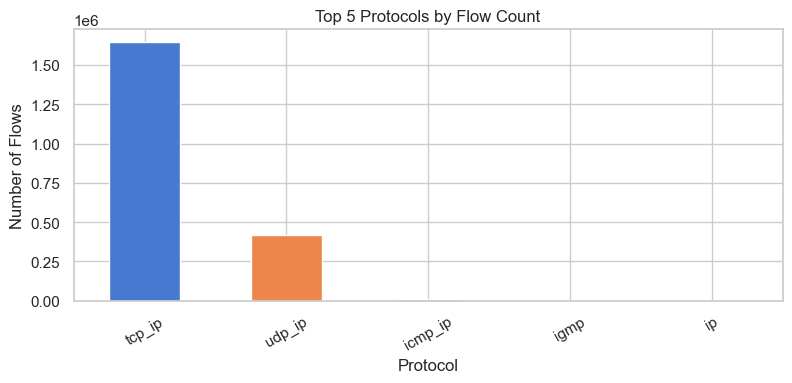

In [5]:
# 1.2 top-k protocols by flow count (change K to adjust)
K = 5
proto_counts = df['protocolName'].value_counts()
top_k_proto  = proto_counts.head(K)

print(f'Top {K} protocols:')
print(top_k_proto.to_string())

fig, ax = plt.subplots(figsize=(8, 4))
top_k_proto.plot(kind='bar', ax=ax, color=sns.color_palette('muted', K))
ax.set_title(f'Top {K} Protocols by Flow Count')
ax.set_xlabel('Protocol')
ax.set_ylabel('Number of Flows')
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_1_2_protocols.png', dpi=150)
plt.show()

Top 10 Source IPs (by bytes sent):
       source  totalSourceBytes
192.168.2.107        1766723841
192.168.4.121         348236805
192.168.2.109         279555269
192.168.1.105         233991932
192.168.1.101         229244162
192.168.2.112         219642794
192.168.2.113         219011411
192.168.4.118         201191844
192.168.1.103         190875178
192.168.2.110         176514136

Top 10 Destination IPs (by bytes received):
    destination  totalDestinationBytes
  192.168.5.122             9583092752
  69.84.133.138             5619014157
 95.154.240.242             3879482850
  68.178.178.97             2801780566
   203.73.24.75             1998532100
  79.125.17.124             1294872433
  68.178.178.33             1222199452
  91.190.170.71             1037257359
     72.32.84.3              784108572
195.189.143.147              752319357


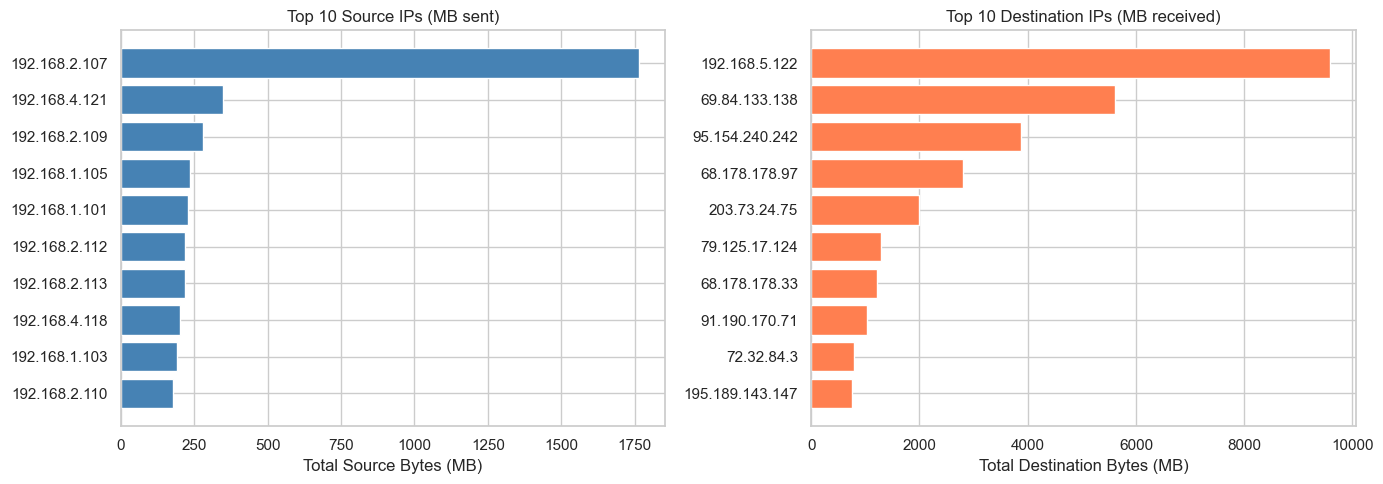

In [6]:
# 1.3 top-10 IPs by total bytes (bytes > flow count for actual bandwidth impact)
top10_src = (df.groupby('source')['totalSourceBytes']
               .sum().nlargest(10)
               .reset_index(name='totalSourceBytes'))

top10_dst = (df.groupby('destination')['totalDestinationBytes']
               .sum().nlargest(10)
               .reset_index(name='totalDestinationBytes'))

print('Top 10 Source IPs (by bytes sent):')
print(top10_src.to_string(index=False))
print()
print('Top 10 Destination IPs (by bytes received):')
print(top10_dst.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(top10_src['source'], top10_src['totalSourceBytes'] / 1e6, color='steelblue')
axes[0].set_title('Top 10 Source IPs (MB sent)')
axes[0].set_xlabel('Total Source Bytes (MB)')
axes[0].invert_yaxis()

axes[1].barh(top10_dst['destination'], top10_dst['totalDestinationBytes'] / 1e6, color='coral')
axes[1].set_title('Top 10 Destination IPs (MB received)')
axes[1].set_xlabel('Total Destination Bytes (MB)')
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_1_3_top10_ips.png', dpi=150)
plt.show()

Mean packet size : 315.79 bytes
Median           : 195.38 bytes
Std dev          : 266.07 bytes
Skewness         : 1.06

Mean is NOT representative - heavy right skew from mixed protocol sizes.
Median is a better central measure for this traffic mix.


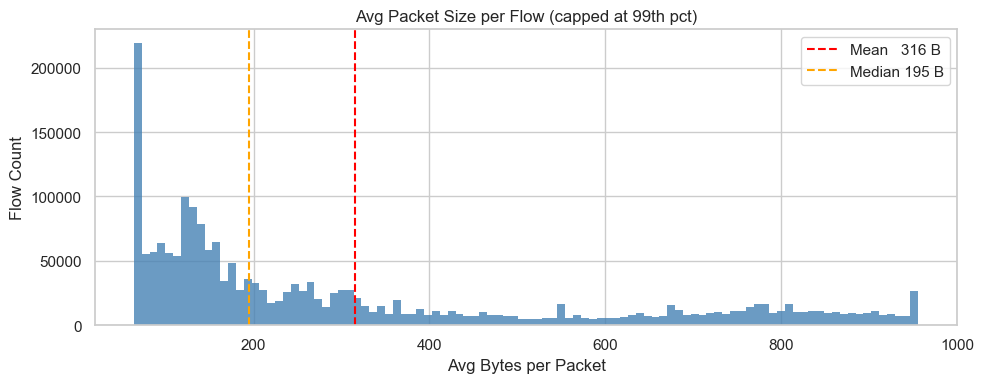

In [7]:
# 1.4 average packet size - check if the mean is actually meaningful
avg_pkt    = df['avg_pkt_bytes'].dropna()
mean_pkt   = avg_pkt.mean()
median_pkt = avg_pkt.median()
std_pkt    = avg_pkt.std()
skew_pkt   = avg_pkt.skew()

print(f'Mean packet size : {mean_pkt:.2f} bytes')
print(f'Median           : {median_pkt:.2f} bytes')
print(f'Std dev          : {std_pkt:.2f} bytes')
print(f'Skewness         : {skew_pkt:.2f}')

if abs(skew_pkt) > 1 or std_pkt > mean_pkt:
    print('\nMean is NOT representative - heavy right skew from mixed protocol sizes.')
    print('Median is a better central measure for this traffic mix.')
else:
    print('\nLow skewness - mean is a reasonable central measure.')

fig, ax = plt.subplots(figsize=(10, 4))
cap = avg_pkt.quantile(0.99)   # cap display at 99th pct
ax.hist(avg_pkt.clip(upper=cap), bins=100, color='steelblue', edgecolor='none', alpha=0.8)
ax.axvline(mean_pkt,   color='red',    linestyle='--', label=f'Mean   {mean_pkt:.0f} B')
ax.axvline(median_pkt, color='orange', linestyle='--', label=f'Median {median_pkt:.0f} B')
ax.set_title('Avg Packet Size per Flow (capped at 99th pct)')
ax.set_xlabel('Avg Bytes per Packet')
ax.set_ylabel('Flow Count')
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_1_4_pkt_size_dist.png', dpi=150)
plt.show()

In [8]:
# 1.5 top-3 source-destination pairs
pair_counts = (df.groupby(['source', 'destination'])
                 .size()
                 .nlargest(3)
                 .reset_index(name='flow_count'))

print('Top 3 Source-Destination Pairs:')
print(pair_counts.to_string(index=False))

Top 3 Source-Destination Pairs:
       source  destination  flow_count
192.168.5.122 198.164.30.2      232409
192.168.2.107 125.6.164.51       58744
192.168.3.115 203.73.24.75       43785


In [9]:
# 1.6 IPs active in >=80% of 1-hour windows
# 1-hour buckets match SIEM aggregation and pick up hourly cron/backup patterns
df_ts = df.dropna(subset=['startDateTime']).copy()
df_ts['hour_window'] = df_ts['startDateTime'].dt.floor('h')

total_windows = df_ts['hour_window'].nunique()
print(f'Distinct 1-hour windows: {total_windows}')

src_window_counts = (df_ts.groupby('source')['hour_window']
                          .nunique()
                          .reset_index(name='windows_active'))

threshold = 0.80 * total_windows
consistent_ips = src_window_counts[src_window_counts['windows_active'] >= threshold]
consistent_ips = consistent_ips.sort_values('windows_active', ascending=False)

print(f'Threshold (80% of {total_windows}): {threshold:.1f} windows')
print(f'Consistently communicating IPs: {len(consistent_ips)}')
print(consistent_ips.head(15).to_string(index=False))

Distinct 1-hour windows: 146
Threshold (80% of 146): 116.8 windows
Consistently communicating IPs: 25
       source  windows_active
192.168.1.101             145
192.168.2.106             145
192.168.1.102             145
192.168.1.103             145
192.168.1.104             145
192.168.2.107             145
192.168.1.105             145
192.168.2.109             145
192.168.2.108             145
192.168.3.116             145
192.168.4.118             145
192.168.2.110             145
192.168.2.111             145
192.168.2.112             145
192.168.2.113             145


Mean: 1197.5  Std: 1265.6  Spike threshold: 3728.7
Spike bins: 92
           bin_5min  flow_count  is_spike
2010-06-13 16:40:00       12550      True
2010-06-13 09:40:00        7598      True
2010-06-13 10:05:00        7570      True
2010-06-13 10:20:00        6940      True
2010-06-13 10:00:00        6718      True
2010-06-13 11:00:00        6614      True
2010-06-13 11:05:00        6258      True
2010-06-13 11:20:00        6004      True
2010-06-13 10:30:00        5992      True
2010-06-15 16:05:00        5961      True


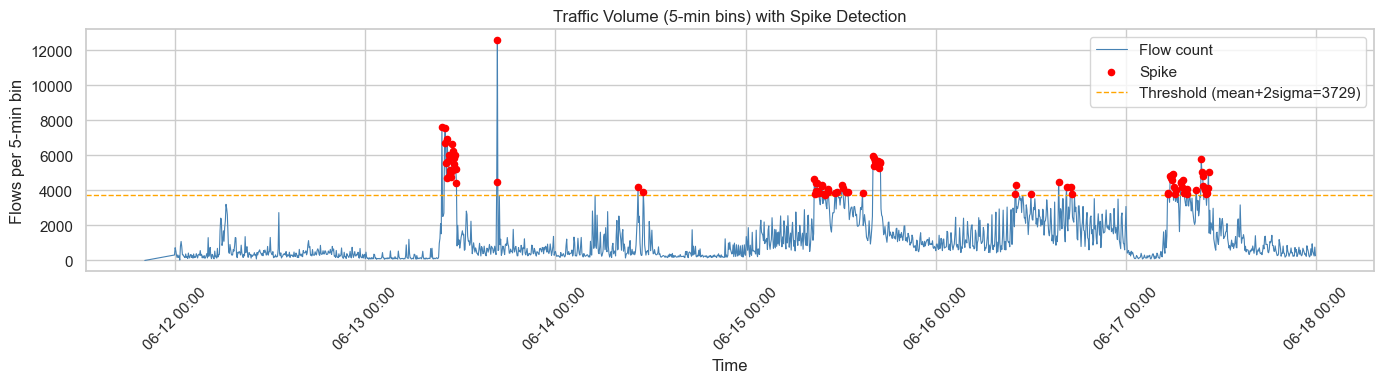

In [10]:
# 1.7 spike detection: flag 5-min bins where flow count > mean + 2*std (z > 2)
df_ts['bin_5min'] = df_ts['startDateTime'].dt.floor('5min')
bin_counts = df_ts.groupby('bin_5min').size().reset_index(name='flow_count')

bin_mean     = bin_counts['flow_count'].mean()
bin_std      = bin_counts['flow_count'].std()
spike_thresh = bin_mean + 2 * bin_std

bin_counts['is_spike'] = bin_counts['flow_count'] > spike_thresh
spikes = bin_counts[bin_counts['is_spike']]

print(f'Mean: {bin_mean:.1f}  Std: {bin_std:.1f}  Spike threshold: {spike_thresh:.1f}')
print(f'Spike bins: {len(spikes)}')
print(spikes.sort_values('flow_count', ascending=False).head(10).to_string(index=False))

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(bin_counts['bin_5min'], bin_counts['flow_count'],
        color='steelblue', linewidth=0.8, label='Flow count')
ax.scatter(spikes['bin_5min'], spikes['flow_count'],
           color='red', zorder=5, s=20, label='Spike')
ax.axhline(spike_thresh, color='orange', linestyle='--', linewidth=1,
           label=f'Threshold (mean+2sigma={spike_thresh:.0f})')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d %H:%M'))
ax.tick_params(axis='x', rotation=45)
ax.set_title('Traffic Volume (5-min bins) with Spike Detection')
ax.set_xlabel('Time')
ax.set_ylabel('Flows per 5-min bin')
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_1_7_spikes.png', dpi=150)
plt.show()

In [11]:
# 1.8 packet size variance
pkt_var = avg_pkt.var()
print(f'Variance : {pkt_var:.2f} bytes^2')
print(f'Std dev  : {math.sqrt(pkt_var):.2f} bytes')
print(f'CV       : {math.sqrt(pkt_var)/avg_pkt.mean():.2f}')
print()
print('High CV is normal for mixed-protocol logs - DNS is tiny, HTTP is mid, bulk transfers near MTU.')
print('Low variance would mean homogeneous traffic, e.g. VoIP or a sensor network.')

Variance : 70795.81 bytes^2
Std dev  : 266.07 bytes
CV       : 0.84

High CV is normal for mixed-protocol logs - DNS is tiny, HTTP is mid, bulk transfers near MTU.
Low variance would mean homogeneous traffic, e.g. VoIP or a sensor network.


---
## Section 2 - Traffic Estimation Using Sublinear Space

### 2a - HyperLogLog: Estimating the Number of Unique IP Addresses

In [12]:
# HyperLogLog (Flajolet et al. 2007)
# hash each IP -> 64 bits, top-b bits pick register, rest gives rho (leftmost 1 pos)
# cardinality estimate = alpha * m^2 / sum(2^-registers), with small/large range fixes

class HyperLogLog:

    _ALPHA = {16: 0.673, 32: 0.697, 64: 0.709}  # bias corrections from the paper

    def __init__(self, b: int = 12):
        # b=12 -> 4096 registers, ~1.6% standard error, 4 KB memory
        self.b = b
        self.m = 1 << b
        self.registers = np.zeros(self.m, dtype=np.int8)
        self.alpha = self._ALPHA.get(self.m, 0.7213 / (1 + 1.079 / self.m))

    def _hash(self, item: str) -> int:
        h = hashlib.md5(item.encode()).digest()
        return int.from_bytes(h[:8], 'big')

    def add(self, item: str):
        x = self._hash(item)
        j   = x >> (64 - self.b)                    # register index
        w   = x & ((1 << (64 - self.b)) - 1)
        rho = (64 - self.b) - int(w).bit_length() + 1 if w else (64 - self.b + 1)
        if rho > self.registers[j]:
            self.registers[j] = rho

    def count(self) -> int:
        Z = 1.0 / np.sum(2.0 ** (-self.registers.astype(float)))
        E = self.alpha * (self.m ** 2) * Z
        # small-range correction when many registers are empty
        if E <= 2.5 * self.m:
            V = np.sum(self.registers == 0)
            if V > 0:
                E = self.m * math.log(self.m / V)
        return int(E)


hll = HyperLogLog(b=12)

print('Adding IPs to HyperLogLog ...')
for ip in df['source'].dropna():
    hll.add(str(ip))
for ip in df['destination'].dropna():
    hll.add(str(ip))

hll_estimate = hll.count()

exact_unique   = len(set(df['source'].dropna().astype(str))
                     | set(df['destination'].dropna().astype(str)))
error_rate     = abs(hll_estimate - exact_unique) / exact_unique * 100
hll_space_kb   = hll.m * 1 / 1024
exact_space_kb = exact_unique * 16 / 1024

print(f'HLL estimate  : {hll_estimate:,}')
print(f'Exact count   : {exact_unique:,}')
print(f'Error         : {error_rate:.2f}%  (target <= 10%)')
print(f'HLL space     : {hll_space_kb:.2f} KB  vs  exact set: {exact_space_kb:.2f} KB  ({exact_space_kb/hll_space_kb:.0f}x smaller)')

Adding IPs to HyperLogLog ...
HLL estimate  : 34,763
Exact count   : 34,801
Error         : 0.11%  (target <= 10%)
HLL space     : 4.00 KB  vs  exact set: 543.77 KB  (136x smaller)


### 2b - Count-Min Sketch: Identifying Frequently Contacted Destination IPs

In [13]:
# Count-Min Sketch (Cormode & Muthukrishnan 2005)
# d rows x w cols; query = min across all rows - upper bound, never undercounts
# d=5, w=10000 -> ~200 KB; error eps=e/w~0.00027 with prob >= 1-e^(-5)~99.3%

class CountMinSketch:

    def __init__(self, d: int = 5, w: int = 10_000):
        self.d = d
        self.w = w
        self.table  = np.zeros((d, w), dtype=np.int32)
        self._seeds = [i * 2654435761 for i in range(1, d + 1)]

    def _hash(self, item: str, seed: int) -> int:
        h = int(hashlib.md5((str(seed) + item).encode()).hexdigest(), 16)
        return h % self.w

    def update(self, item: str, count: int = 1):
        for i, seed in enumerate(self._seeds):
            col = self._hash(item, seed)
            self.table[i, col] += count

    def query(self, item: str) -> int:
        return min(self.table[i, self._hash(item, seed)]
                   for i, seed in enumerate(self._seeds))


print('Building Count-Min Sketch over destination IPs ...')
cms = CountMinSketch(d=5, w=10_000)
dst_series = df['destination'].dropna().astype(str)
for ip in dst_series:
    cms.update(ip)

print('Computing exact destination IP counts ...')
exact_dst_counts = dst_series.value_counts()

total_flows  = len(df)
hh_threshold = total_flows / 100   # heavy hitter = top 1%

unique_dsts  = exact_dst_counts.index.tolist()
sketch_counts = {ip: cms.query(ip) for ip in unique_dsts}
sketch_hh     = {ip: cnt for ip, cnt in sketch_counts.items() if cnt >= hh_threshold}
exact_hh      = exact_dst_counts[exact_dst_counts >= hh_threshold]

print(f'Heavy-hitter threshold: {hh_threshold:.0f} flows (1% of {total_flows:,})')
print(f'Sketch HH: {len(sketch_hh)}  |  Exact HH: {len(exact_hh)}')

top20_exact = exact_dst_counts.head(20)
comparison  = pd.DataFrame({
    'IP':           top20_exact.index,
    'exact_count':  top20_exact.values,
    'sketch_count': [cms.query(ip) for ip in top20_exact.index]
})
comparison['abs_error'] = (comparison['sketch_count'] - comparison['exact_count']).abs()
comparison['pct_error'] = comparison['abs_error'] / comparison['exact_count'] * 100

mean_pct_err = comparison['pct_error'].mean()
print(f'\nTop-20 IPs comparison (mean % error: {mean_pct_err:.4f}%):')
print(comparison.to_string(index=False))

cms_space_kb   = 5 * 10_000 * 4 / 1024
exact_space_kb2 = len(unique_dsts) * (16 + 8) / 1024
print(f'\nCMS: {cms_space_kb:.1f} KB  |  Exact dict: ~{exact_space_kb2:.1f} KB')

Building Count-Min Sketch over destination IPs ...
Computing exact destination IP counts ...
Heavy-hitter threshold: 20717 flows (1% of 2,071,657)
Sketch HH: 9  |  Exact HH: 9

Top-20 IPs comparison (mean % error: 0.0181%):
             IP  exact_count  sketch_count  abs_error  pct_error
   198.164.30.2       232409        232411          2   0.000861
  192.168.5.122       199437        199440          3   0.001504
   203.73.24.75       193200        193200          0   0.000000
   125.6.164.51       106826        106828          2   0.001872
  67.220.214.50        49298         49299          1   0.002028
202.210.143.140        36189         36200         11   0.030396
   82.98.86.183        25214         25216          2   0.007932
   95.211.98.12        25095         25100          5   0.019924
  209.112.44.10        21824         21825          1   0.004582
 62.140.213.243        20509         20513          4   0.019504
   64.38.193.26        20015         20017          2   0.009

### 2c - Bloom Filter: Efficient Membership Testing for Blocklists

In [14]:
# Bloom filter (Bloom 1970)
# m = -n*ln(p)/ln(2)^2 bits, k = m/n*ln(2) hash functions
# insert all known source IPs, then probe random IPs to measure actual FPR

try:
    from bitarray import bitarray
    HAS_BITARRAY = True
except ImportError:
    HAS_BITARRAY = False
    print('bitarray not installed; using bytearray fallback.')


class BloomFilter:

    def __init__(self, n: int, fpr: float = 0.01):
        self.n   = n
        self.fpr = fpr
        self.m   = math.ceil(-n * math.log(fpr) / (math.log(2) ** 2))
        self.k   = max(1, round(self.m / n * math.log(2)))

        if HAS_BITARRAY:
            self._bits = bitarray(self.m)
            self._bits.setall(0)
        else:
            self._bits = bytearray(math.ceil(self.m / 8))

        print(f'Bloom filter: n={n:,}, target FPR={fpr*100:.1f}%')
        print(f'  m={self.m:,} bits ({self.m/8/1024:.1f} KB), k={self.k} hash functions')

    def _get_bit(self, i):
        return self._bits[i] if HAS_BITARRAY else (self._bits[i >> 3] >> (i & 7)) & 1

    def _set_bit(self, i):
        if HAS_BITARRAY:
            self._bits[i] = 1
        else:
            self._bits[i >> 3] |= (1 << (i & 7))

    def _hashes(self, item: str):
        # double-hashing (MD5 + SHA256) approximates k independent hash functions
        h1 = int(hashlib.md5(item.encode()).hexdigest(), 16)
        h2 = int(hashlib.sha256(item.encode()).hexdigest(), 16)
        for i in range(self.k):
            yield (h1 + i * h2) % self.m

    def add(self, item: str):
        for idx in self._hashes(item):
            self._set_bit(idx)

    def __contains__(self, item: str) -> bool:
        return all(self._get_bit(idx) for idx in self._hashes(item))


all_src_ips = list(df['source'].dropna().astype(str).unique())
n_total     = len(all_src_ips)

bf = BloomFilter(n=n_total, fpr=0.01)
print(f'Inserting {n_total:,} unique source IPs ...')
for ip in all_src_ips:
    bf.add(ip)

fn_count = sum(1 for ip in all_src_ips if ip not in bf)
print(f'False negatives on inserted IPs: {fn_count}  (expected: 0)')

# probe random IPs that are definitely not in the dataset
import random, ipaddress
random.seed(42)
all_known_ips = set(df['source'].dropna().astype(str)) | set(df['destination'].dropna().astype(str))
N_PROBE    = 100_000
random_ips = []
while len(random_ips) < N_PROBE:
    candidate = str(ipaddress.IPv4Address(random.randint(0, 2**32 - 1)))
    if candidate not in all_known_ips:
        random_ips.append(candidate)

fp_count   = sum(1 for ip in random_ips if ip in bf)
actual_fpr = fp_count / N_PROBE

exact_set  = set(all_src_ips)
exact_fp   = sum(1 for ip in random_ips if ip in exact_set)

bf_space_kb  = bf.m / 8 / 1024
set_space_kb = (200 + n_total * 50) / 1024   # ~50 bytes per Python str entry

print(f'False negatives        : {fn_count}')
print(f'False positives/{N_PROBE:,} : {fp_count}')
print(f'Actual FPR             : {actual_fpr*100:.3f}%  (target <= 1%)')
print(f'Bloom filter space     : {bf_space_kb:.1f} KB')
print(f'Python set space       : {set_space_kb:.1f} KB  ({set_space_kb/bf_space_kb:.0f}x larger)')

Bloom filter: n=2,478, target FPR=1.0%
  m=23,752 bits (2.9 KB), k=7 hash functions
Inserting 2,478 unique source IPs ...
False negatives on inserted IPs: 0  (expected: 0)
False negatives        : 0
False positives/100,000 : 982
Actual FPR             : 0.982%  (target <= 1%)
Bloom filter space     : 2.9 KB
Python set space       : 121.2 KB  (42x larger)


---
## Section 3 - Advanced Anomaly Detection

### 3a - Statistical Traffic Analysis

Packet size IQR bounds: [-389.6, 966.6] bytes
Flows above upper fence: 14,483

Per-IP flow count IQR: [-2.0, 6.0]
Source IPs with abnormally high flow count: 304
source
192.168.5.122    268267
192.168.2.107    208379
192.168.4.118    135374
192.168.1.101    116292
192.168.4.121    105454
192.168.1.105    101359
192.168.2.109     99183
192.168.3.116     97241
192.168.2.110     90658
192.168.3.115     88915

Hours with anomalous protocol distribution: 17

IPs > mean+3sigma (1123.7 MB):
source
192.168.2.109    7369281030
192.168.1.101    6353065591
192.168.2.112    5759816514
192.168.1.103    5392234742
192.168.2.107    4861094682
192.168.2.113    4811521438
192.168.4.118    4006130354
192.168.4.121    3749783991
192.168.1.102    3719467167
192.168.2.110    3642212173


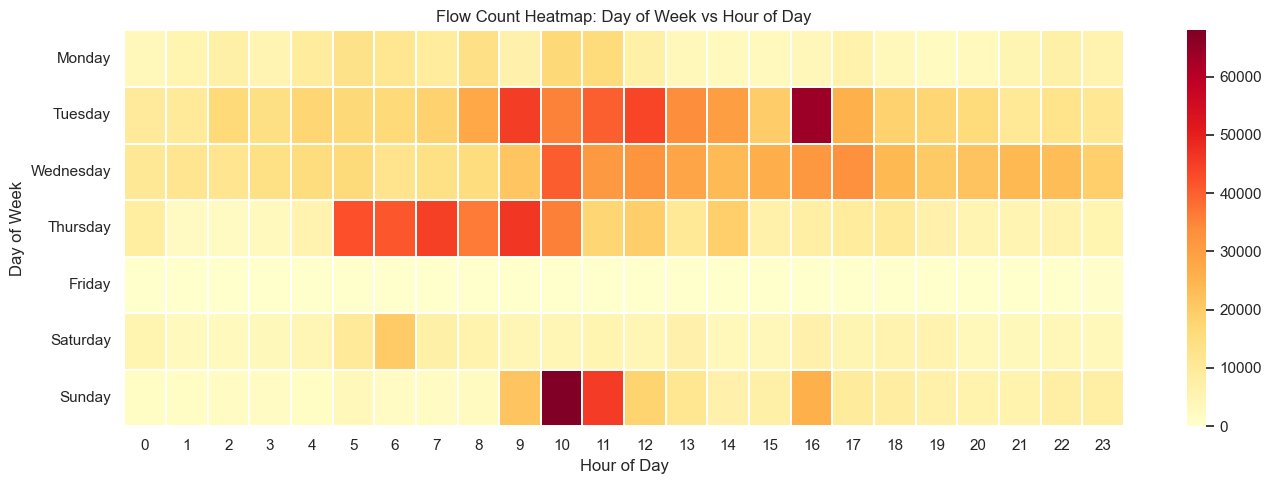

In [15]:
# 3a statistical anomaly detection
# IQR fences for packet sizes, z-score for per-IP byte volume, protocol shift check

def iqr_bounds(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


pkt_lo, pkt_hi = iqr_bounds(df['avg_pkt_bytes'].dropna())
pkt_anomalies  = df[df['avg_pkt_bytes'] > pkt_hi]
print(f'Packet size IQR bounds: [{pkt_lo:.1f}, {pkt_hi:.1f}] bytes')
print(f'Flows above upper fence: {len(pkt_anomalies):,}')

ip_flow_counts = df['source'].value_counts()
fc_lo, fc_hi   = iqr_bounds(ip_flow_counts)
high_flow_ips  = ip_flow_counts[ip_flow_counts > fc_hi]
print(f'\nPer-IP flow count IQR: [{fc_lo:.1f}, {fc_hi:.1f}]')
print(f'Source IPs with abnormally high flow count: {len(high_flow_ips)}')
print(high_flow_ips.head(10).to_string())

df_ts2 = df.dropna(subset=['startDateTime']).copy()
df_ts2['hour'] = df_ts2['startDateTime'].dt.floor('h')
df_ts2['date'] = df_ts2['startDateTime'].dt.date

hourly_proto = (df_ts2.groupby(['hour', 'protocolName'])
                       .size().unstack(fill_value=0))
hourly_share = hourly_proto.div(hourly_proto.sum(axis=1), axis=0)

# flag hours where any protocol share shifts > 2 sigma from its mean
proto_mean = hourly_share.mean()
proto_std  = hourly_share.std()
anomalous_hours = ((hourly_share - proto_mean).abs() > 2 * proto_std).any(axis=1)
print(f'\nHours with anomalous protocol distribution: {anomalous_hours.sum()}')

# per-IP byte outliers: z-score threshold of 3
ip_bytes  = df.groupby('source')['totalBytes'].sum()
byte_mean = ip_bytes.mean()
byte_std  = ip_bytes.std()
outlier_ips = ip_bytes[ip_bytes > byte_mean + 3 * byte_std]
print(f'\nIPs > mean+3sigma ({(byte_mean+3*byte_std)/1e6:.1f} MB):')
print(outlier_ips.sort_values(ascending=False).head(10).to_string())

# heatmap
df_ts2['day_of_week'] = df_ts2['startDateTime'].dt.day_name()
df_ts2['hour_of_day'] = df_ts2['startDateTime'].dt.hour
heatmap_data = (df_ts2.groupby(['day_of_week', 'hour_of_day'])
                       .size().unstack(fill_value=0))
day_order    = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
heatmap_data = heatmap_data.reindex([d for d in day_order if d in heatmap_data.index])

if not heatmap_data.empty:
    fig, ax = plt.subplots(figsize=(14, 5))
    sns.heatmap(heatmap_data, ax=ax, cmap='YlOrRd', linewidths=0.3)
    ax.set_title('Flow Count Heatmap: Day of Week vs Hour of Day')
    ax.set_xlabel('Hour of Day')
    ax.set_ylabel('Day of Week')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / 'fig_3a_heatmap.png', dpi=150)
    plt.show()

### 3b - Behavioural Analysis

In [16]:
# 3b.1 behavioral spike: flag IPs where any hour exceeds 5x their 3-hour rolling mean
df_ts3 = df_ts2.copy()
hourly_src_flows = (df_ts3.groupby(['source', 'hour'])
                           .size().reset_index(name='flow_count'))
hourly_src_flows = hourly_src_flows.sort_values(['source','hour'])
hourly_src_flows['rolling_mean'] = (
    hourly_src_flows.groupby('source')['flow_count']
                    .transform(lambda x: x.shift(1).rolling(3, min_periods=1).mean())
)
hourly_src_flows['spike_ratio'] = (
    hourly_src_flows['flow_count'] /
    hourly_src_flows['rolling_mean'].replace(0, np.nan)
)
behavior_anomalies = hourly_src_flows[
    hourly_src_flows['spike_ratio'] > 5
].sort_values('spike_ratio', ascending=False)

print(f'IP-hour pairs with spike ratio > 5x: {len(behavior_anomalies)}')
print(behavior_anomalies.head(10).to_string(index=False))

IP-hour pairs with spike ratio > 5x: 178
         source                hour  flow_count  rolling_mean  spike_ratio
 131.202.243.90 2010-06-17 14:00:00        5116      3.666667  1395.272727
  192.168.2.110 2010-06-13 10:00:00       11370     38.666667   294.051724
  192.168.2.110 2010-06-17 05:00:00        3267     18.666667   175.017857
131.202.240.209 2010-06-14 16:00:00         491      4.000000   122.750000
  192.168.3.116 2010-06-17 05:00:00        6990     60.333333   115.856354
  192.168.2.107 2010-06-17 05:00:00        2889     27.666667   104.421687
  192.168.2.106 2010-06-13 09:00:00        5664     64.666667    87.587629
  192.168.3.115 2010-06-15 00:00:00        1021     12.333333    82.783784
  192.168.2.110 2010-06-12 00:00:00        1685     21.000000    80.238095
  192.168.4.120 2010-06-12 00:00:00         616      8.000000    77.000000


In [17]:
# 3b.2/3b.3 fan-in: destinations hit by >=20 distinct sources in a 5-min window
df_fan = df_ts3.copy()
df_fan['bin_5min'] = df_fan['startDateTime'].dt.floor('5min')

fan_in = (df_fan.groupby(['destination', 'bin_5min'])['source']
                .nunique().reset_index(name='distinct_sources'))
ddos_candidates = fan_in[fan_in['distinct_sources'] >= 20]
ddos_candidates = ddos_candidates.sort_values('distinct_sources', ascending=False)

print(f'Destinations with >=20 distinct sources in a 5-min window:')
print(f'Total events: {len(ddos_candidates)}')
print(ddos_candidates.head(15).to_string(index=False))
print(f'\nUnique destinations flagged: {ddos_candidates["destination"].nunique()}')

Destinations with >=20 distinct sources in a 5-min window:
Total events: 474
  destination            bin_5min  distinct_sources
192.168.2.107 2010-06-15 07:55:00               144
192.168.2.107 2010-06-15 01:55:00               139
192.168.2.107 2010-06-15 02:55:00               135
192.168.2.107 2010-06-15 05:55:00               133
192.168.2.107 2010-06-15 03:20:00               132
192.168.2.107 2010-06-15 06:20:00               120
192.168.2.107 2010-06-15 02:10:00               118
192.168.2.107 2010-06-15 04:25:00               118
192.168.2.107 2010-06-15 07:25:00               116
192.168.2.107 2010-06-15 04:55:00               113
192.168.2.107 2010-06-15 02:05:00               106
192.168.2.107 2010-06-15 02:00:00                98
192.168.2.107 2010-06-15 07:10:00                96
192.168.2.107 2010-06-15 05:10:00                95
192.168.2.107 2010-06-15 05:40:00                94

Unique destinations flagged: 2


### 3c - Suspicious Communication Patterns

In [18]:
# 3c.1 long-duration flows: flag anything > mean + 3-sigma (possible tunnel or backdoor)
dur_mean   = df['duration_s'].mean()
dur_std    = df['duration_s'].std()
dur_thresh = dur_mean + 3 * dur_std

long_flows = df[df['duration_s'] > dur_thresh].sort_values('duration_s', ascending=False)
print(f'Duration mean: {dur_mean:.2f}s  std: {dur_std:.2f}s  threshold: {dur_thresh:.2f}s')
print(f'Long-duration flows: {len(long_flows):,}')
print(long_flows[['source','destination','protocolName','duration_s',
                  'totalBytes','Label']].head(15).to_string(index=False))

Duration mean: 48.99s  std: 619.77s  threshold: 1908.29s
Long-duration flows: 7,628
       source     destination protocolName  duration_s  totalBytes  Label
192.168.1.101   192.168.1.255       udp_ip     49140.0      163332 Normal
192.168.1.101 255.255.255.255       udp_ip     49140.0      163332 Normal
192.168.2.109 255.255.255.255       udp_ip     48960.0      163020 Normal
192.168.2.109   192.168.2.255       udp_ip     48960.0      163020 Normal
192.168.2.112   192.168.2.109       tcp_ip     48900.0      511364 Normal
192.168.2.112   192.168.2.255       udp_ip     48900.0      163176 Normal
192.168.2.112 255.255.255.255       udp_ip     48900.0      163176 Normal
192.168.3.117 255.255.255.255       udp_ip     48780.0      164268 Normal
192.168.3.117   192.168.3.255       udp_ip     48780.0      164268 Normal
192.168.3.114   192.168.3.255       udp_ip     48780.0      163956 Normal
192.168.3.114 255.255.255.255       udp_ip     48780.0      163956 Normal
192.168.3.117   192.168.3.11

In [19]:
# 3c.2 multi-protocol burst: >2 protocols in 60s - scanners and malware do this
df_mp = df_ts3.copy()
df_mp['bin_60s'] = df_mp['startDateTime'].dt.floor('60s')

multi_proto = (df_mp.groupby(['source', 'bin_60s'])['protocolName']
                    .nunique().reset_index(name='distinct_protocols'))
multi_proto_suspicious = multi_proto[multi_proto['distinct_protocols'] > 2]
multi_proto_suspicious = multi_proto_suspicious.sort_values(
    'distinct_protocols', ascending=False)

print(f'IP-minute pairs using >2 distinct protocols in 60s:')
print(f'Total events: {len(multi_proto_suspicious)}')
print(multi_proto_suspicious.head(15).to_string(index=False))
print(f'\nUnique source IPs flagged: {multi_proto_suspicious["source"].nunique()}')

IP-minute pairs using >2 distinct protocols in 60s:
Total events: 108
       source             bin_60s  distinct_protocols
192.168.1.101 2010-06-13 10:06:00                   3
192.168.1.105 2010-06-13 09:40:00                   3
192.168.1.105 2010-06-13 16:38:00                   3
192.168.1.105 2010-06-13 16:42:00                   3
192.168.2.107 2010-06-14 21:50:00                   3
192.168.2.107 2010-06-14 21:54:00                   3
192.168.2.107 2010-06-15 09:11:00                   3
192.168.2.112 2010-06-13 16:58:00                   3
192.168.2.112 2010-06-14 17:19:00                   3
192.168.3.117 2010-06-16 09:55:00                   3
192.168.4.120 2010-06-14 07:57:00                   3
192.168.4.121 2010-06-12 03:09:00                   3
192.168.4.121 2010-06-12 04:27:00                   3
192.168.4.121 2010-06-12 05:22:00                   3
192.168.4.121 2010-06-12 11:29:00                   3

Unique source IPs flagged: 8


---
## Section 4 - Deep Security Threat Analysis

### 4a - Detecting Complex Attack Patterns

In [20]:
# 4a.1 stealthy port scan: >=30 distinct ports on same target, span >=10 min, rate <5/min
# slow rate keeps it below IDS threshold triggers
df_scan = df_ts3.copy()

port_scan_candidates = (df_scan.groupby(['source', 'destination'])
                               .agg(
                                   distinct_ports=('destinationPort', 'nunique'),
                                   flow_count=('destinationPort', 'count'),
                                   start=('startDateTime', 'min'),
                                   end=('startDateTime', 'max')
                               ).reset_index())

port_scan_candidates['span_min'] = (
    (port_scan_candidates['end'] - port_scan_candidates['start'])
    .dt.total_seconds() / 60
)
port_scan_candidates['rate_per_min'] = (
    port_scan_candidates['flow_count'] /
    port_scan_candidates['span_min'].replace(0, np.nan)
)

stealthy_scans = port_scan_candidates[
    (port_scan_candidates['distinct_ports'] >= 30) &
    (port_scan_candidates['span_min'] >= 10) &
    (port_scan_candidates['rate_per_min'] < 5)
].sort_values('distinct_ports', ascending=False)

print(f'Stealthy port scan candidates: {len(stealthy_scans)}')
print(stealthy_scans.head(15).to_string(index=False))

Stealthy port scan candidates: 25
       source   destination  distinct_ports  flow_count               start                 end  span_min  rate_per_min
192.168.4.121 192.168.5.122            3658       19783 2010-06-11 23:59:00 2010-06-17 23:58:00    8639.0      2.289964
192.168.1.105 192.168.2.112             824        1829 2010-06-13 16:42:00 2010-06-15 15:27:00    2805.0      0.652050
192.168.2.112 192.168.5.122             664       11669 2010-06-11 23:59:00 2010-06-17 23:58:00    8639.0      1.350735
192.168.4.118 192.168.5.122             639       12236 2010-06-11 23:59:00 2010-06-17 23:57:00    8638.0      1.416532
192.168.1.105 192.168.5.122             606       10525 2010-06-11 23:59:00 2010-06-17 23:55:00    8636.0      1.218736
192.168.3.114 192.168.5.122             589        3969 2010-06-11 23:59:00 2010-06-17 23:51:00    8632.0      0.459801
192.168.2.113 192.168.5.122             564       18236 2010-06-12 00:01:00 2010-06-17 23:57:00    8636.0      2.111626
192.16

In [21]:
# 4a.2 slow DDoS: distinct source count grows monotonically >=3h, peak >=5, ratio >=1.5x
df_ddos = df_ts3.copy()
hourly_dst_src = (df_ddos.groupby(['destination', 'hour'])['source']
                          .nunique().reset_index(name='distinct_srcs'))
hourly_dst_src = hourly_dst_src.sort_values(['destination', 'hour'])


def max_monotonic_run(series, min_run=3, min_peak=5, min_growth_ratio=1.5):
    # longest strictly increasing run meeting peak and growth thresholds
    arr = series.values
    best = None
    run_start_idx = 0
    run_len = 1
    for i in range(1, len(arr)):
        if arr[i] > arr[i - 1]:
            run_len += 1
        else:
            if run_len >= min_run:
                start_v = arr[run_start_idx]
                end_v   = arr[i - 1]
                if (end_v >= min_peak and
                        start_v > 0 and end_v / start_v >= min_growth_ratio):
                    if best is None or run_len > best[2]:
                        best = (start_v, end_v, run_len)
            run_start_idx = i
            run_len = 1
    if run_len >= min_run:
        start_v = arr[run_start_idx]
        end_v   = arr[-1]
        if (end_v >= min_peak and
                start_v > 0 and end_v / start_v >= min_growth_ratio):
            if best is None or run_len > best[2]:
                best = (start_v, end_v, run_len)
    return best


slow_ddos_results = []
for dst, grp in hourly_dst_src.groupby('destination'):
    result = max_monotonic_run(
        grp['distinct_srcs'].reset_index(drop=True),
        min_run=3, min_peak=5, min_growth_ratio=1.5
    )
    if result:
        slow_ddos_results.append({
            'destination':    dst,
            'run_start_srcs': result[0],
            'run_peak_srcs':  result[1],
            'run_hours':      result[2],
            'growth_ratio':   round(result[1] / result[0], 2)
        })

slow_ddos_df = pd.DataFrame(slow_ddos_results).sort_values('run_peak_srcs', ascending=False)
slow_ddos    = slow_ddos_df['destination'].values

print(f'Slow DDoS candidates: {len(slow_ddos_df)}')
print(slow_ddos_df.head(15).to_string(index=False))

Slow DDoS candidates: 175
    destination  run_start_srcs  run_peak_srcs  run_hours  growth_ratio
  192.168.2.107               1            183          3        183.00
  142.166.14.80               6             15          6          2.50
  142.166.14.71               1             15          5         15.00
  142.166.14.69               3             14          5          4.67
  142.166.14.78               2             13          5          6.50
  142.166.14.86               2             13          5          6.50
206.123.111.173               1             13          5         13.00
  142.166.14.77               1             12          6         12.00
  142.166.14.70               7             12          5          1.71
  142.166.14.79               3             11          4          3.67
 142.176.121.88               1              9          4          9.00
  72.14.204.104               1              9          4          9.00
 64.202.189.170               2       

In [22]:
# 4a.3 IP hopping: cluster source IPs that share >=50% of their destination targets
# use dst-only fingerprint - ephemeral source ports change, destination hosts don't

fp = {}
for src, grp in df[['source', 'destination']].dropna().groupby('source'):
    dsts = frozenset(grp['destination'].astype(str).unique())
    if len(dsts) >= 3:      # require at least 3 distinct targets
        fp[str(src)] = dsts

print(f'Source IPs with >=3 distinct destinations: {len(fp):,}')

# pre-filter pairs that share at least one destination - avoids full O(n^2) sweep
dst_to_srcs = defaultdict(list)
for src, dsts in fp.items():
    for dst in dsts:
        dst_to_srcs[dst].append(src)

candidate_pairs = set()
for srcs in dst_to_srcs.values():
    for i in range(min(len(srcs), 50)):
        for j in range(i + 1, min(len(srcs), 50)):
            pair = tuple(sorted([srcs[i], srcs[j]]))
            candidate_pairs.add(pair)

print(f'Candidate pairs to evaluate: {len(candidate_pairs):,}')


def jaccard(a, b):
    inter = len(a & b)
    return inter / len(a | b) if (a | b) else 0.0


JACC_THRESH  = 0.50
similar_pairs = [(a, b, jaccard(fp[a], fp[b]))
                 for a, b in candidate_pairs
                 if jaccard(fp[a], fp[b]) >= JACC_THRESH]

print(f'Similar pairs (Jaccard >= {JACC_THRESH}): {len(similar_pairs)}')

# union-find clustering
parent = {}
def find(x):
    parent.setdefault(x, x)
    if parent[x] != x:
        parent[x] = find(parent[x])
    return parent[x]
def union(x, y):
    parent[find(x)] = find(y)

for a, b, _ in similar_pairs:
    union(a, b)

clusters = defaultdict(list)
for src in fp:
    clusters[find(src)].append(src)

ip_hop_clusters = {k: sorted(v) for k, v in clusters.items() if len(v) >= 3}

print(f'IP hopping clusters (>=3 IPs, Jaccard >= {JACC_THRESH}): {len(ip_hop_clusters)}')
for rep, members in list(ip_hop_clusters.items())[:8]:
    common = fp[members[0]]
    for m in members[1:]:
        common = common & fp[m]
    print(f'  [{len(members)} IPs] shared targets: {len(common)}  members: {members[:6]}')

Source IPs with >=3 distinct destinations: 35
Candidate pairs to evaluate: 462
Similar pairs (Jaccard >= 0.5): 6
IP hopping clusters (>=3 IPs, Jaccard >= 0.5): 1
  [4 IPs] shared targets: 10  members: ['142.166.115.13', '142.166.185.154', '192.168.5.124', '64.237.127.131']


In [23]:
# free intermediates before 4b - payload scans + C2 detection are memory-hungry
import gc
for _v in ["df_ts", "df_ts2", "df_fan", "df_mp", "df_ddos", "df_scan", "port_scan_candidates"]:
    if _v in dir(): del globals()[_v]
gc.collect()
print("intermediate DataFrames freed")

intermediate DataFrames freed


### 4b - Malicious Payload Identification

In [24]:
# 4b.1 scan payload fields for known attack strings
SUSPICIOUS_PATTERNS = [
    (r'/bin/sh|/bin/bash|cmd\.exe|powershell',    'shell_command'),
    (r'wget |curl |nc |ncat |netcat ',             'download_or_backdoor'),
    (r'\bSELECT\b.*\bFROM\b|UNION ALL SELECT',   'sql_injection'),
    (r'<script[^>]*>|javascript:',                 'xss'),
    (r'User-Agent.*[Bb]ot|[Ss]canner|[Mm]assscan', 'scanner_ua'),
    (r'(?:password|passwd|secret)\s*=',            'credential_leak'),
    (r'(?:[A-Za-z0-9+/]{40,}={0,2})(?!\w)',       'large_base64_blob'),
]


def scan_payloads(df_in, col):
    results = []
    series  = df_in[col].dropna().astype(str)
    for pattern, label in SUSPICIOUS_PATTERNS:
        mask  = series.str.contains(pattern, regex=True, case=False, na=False)
        count = mask.sum()
        if count > 0:
            results.append({'pattern': label, 'column': col, 'matches': int(count)})
    return results


payload_findings = []
for col in ['sourcePayloadAsUTF', 'destinationPayloadAsUTF']:
    payload_findings.extend(scan_payloads(df, col))

if payload_findings:
    pf_df = pd.DataFrame(payload_findings).sort_values('matches', ascending=False)
    print('Suspicious payload patterns found:')
    print(pf_df.to_string(index=False))
else:
    print('No suspicious payload patterns detected.')

Suspicious payload patterns found:
             pattern                  column  matches
                 xss destinationPayloadAsUTF    58490
   large_base64_blob      sourcePayloadAsUTF    37398
   large_base64_blob destinationPayloadAsUTF    36610
          scanner_ua destinationPayloadAsUTF    15973
download_or_backdoor destinationPayloadAsUTF     1885
download_or_backdoor      sourcePayloadAsUTF      107
          scanner_ua      sourcePayloadAsUTF       93
     credential_leak destinationPayloadAsUTF       39
       sql_injection destinationPayloadAsUTF       14
                 xss      sourcePayloadAsUTF        3
       shell_command      sourcePayloadAsUTF        2
     credential_leak      sourcePayloadAsUTF        1


In [25]:
# 4b.2 anomalous encrypted traffic (SecureWeb/SSH/IPSec/Authentication)
# appName identifies encrypted apps; protocolName is always tcp_ip/udp_ip (transport only)
# flags: tiny payload <100B, sub-second duration, IQR outliers within the encrypted subset

ENCRYPTED_APPS = {'SecureWeb', 'SSH', 'IPSec', 'Authentication'}
encrypted = df[df['appName'].isin(ENCRYPTED_APPS)].copy()

print(f'Encrypted-app flows:')
print(encrypted['appName'].value_counts().to_string())
print(f'\nTotal: {len(encrypted):,}  ({len(encrypted)/len(df)*100:.2f}% of all flows)')

# small payload
enc_small = encrypted[encrypted['totalBytes'] < 100]
print(f'\nEncrypted flows <100B total payload: {len(enc_small):,}')
if len(enc_small) > 0:
    print(enc_small[['source', 'destination', 'appName',
                      'totalBytes', 'duration_s']].head(10).to_string(index=False))

# sub-second duration
enc_short = encrypted[encrypted['duration_s'] < 1]
print(f'\nEncrypted flows <1s duration: {len(enc_short):,}')
if len(enc_short) > 0:
    print(enc_short[['source', 'destination', 'appName',
                      'totalBytes', 'duration_s']].head(10).to_string(index=False))

# IQR outliers within encrypted subset
if len(encrypted) > 10:
    enc_lo, enc_hi = iqr_bounds(encrypted['avg_pkt_bytes'].dropna())
    enc_pkt_anomalies = encrypted[
        (encrypted['avg_pkt_bytes'] < enc_lo) | (encrypted['avg_pkt_bytes'] > enc_hi)
    ]
    print(f'\nEncrypted flows with anomalous packet size (IQR): {len(enc_pkt_anomalies):,}')
    print(f'Normal encrypted packet-size range: [{enc_lo:.1f}, {enc_hi:.1f}] bytes')
    print(enc_pkt_anomalies[['source', 'destination', 'appName',
                              'avg_pkt_bytes', 'totalBytes', 'duration_s']
                             ].sort_values('avg_pkt_bytes', ascending=False
                             ).head(10).to_string(index=False))
else:
    print('Too few encrypted flows for IQR analysis.')

# beaconing within encrypted traffic
if len(encrypted) > 5:
    enc_c2 = encrypted.dropna(subset=['startDateTime']).sort_values('startDateTime')
    enc_c2['iat_s'] = (enc_c2.groupby(['source', 'destination'])['startDateTime']
                              .diff().dt.total_seconds())
    enc_beacon = (enc_c2.groupby(['source', 'destination', 'appName'])
                        .agg(flow_count=('startDateTime','count'),
                             iat_mean=('iat_s','mean'),
                             iat_std=('iat_s','std'))
                        .reset_index())
    enc_beacon['iat_cv'] = enc_beacon['iat_std'] / enc_beacon['iat_mean'].replace(0, np.nan)
    enc_beacon_candidates = enc_beacon[
        (enc_beacon['flow_count'] >= 5) & (enc_beacon['iat_cv'] < 0.3)
    ].sort_values('iat_cv')
    print(f'\nEncrypted beaconing candidates (>=5 flows, IAT CV < 0.3): {len(enc_beacon_candidates)}')
    if len(enc_beacon_candidates) > 0:
        print(enc_beacon_candidates.head(10).to_string(index=False))

Encrypted-app flows:
appName
SecureWeb         57216
SSH                9992
Authentication      240
IPSec                94

Total: 67,542  (3.26% of all flows)

Encrypted flows <100B total payload: 1,646
       source     destination   appName  totalBytes  duration_s
192.168.4.119  174.137.114.40 SecureWeb          64         0.0
192.168.4.121  66.180.194.135 SecureWeb          64         0.0
192.168.4.121  66.180.194.135 SecureWeb          64         0.0
192.168.3.116  64.202.189.148 SecureWeb          64         0.0
192.168.3.116    97.74.43.117 SecureWeb          64         0.0
192.168.4.121  66.180.194.135 SecureWeb          64         0.0
192.168.2.108 208.131.147.206 SecureWeb          64         0.0
192.168.3.115 210.136.232.195 SecureWeb          64         0.0
192.168.2.112     211.0.63.57 SecureWeb          64         0.0
192.168.3.115  111.89.136.165 SecureWeb          64         0.0

Encrypted flows <1s duration: 49,950
       source   destination appName  totalBytes  dur

In [26]:
# 4b.3 C2 beaconing: periodic small-payload connections, IAT CV < 0.3 (low jitter = timer-driven)
df_c2 = df_ts3[["source", "destination", "startDateTime", "totalBytes"]].sort_values("startDateTime")
df_c2['iat_s'] = (df_c2.groupby(['source','destination'])['startDateTime']
                        .diff().dt.total_seconds())

c2_stats = (df_c2.groupby(['source','destination'])
                  .agg(
                      flow_count=('startDateTime', 'count'),
                      iat_mean=('iat_s', 'mean'),
                      iat_std=('iat_s', 'std'),
                      avg_payload=('totalBytes', 'mean')
                  ).reset_index())

c2_stats['iat_cv'] = c2_stats['iat_std'] / c2_stats['iat_mean'].replace(0, np.nan)

c2_beacons = c2_stats[
    (c2_stats['flow_count'] >= 5) &
    (c2_stats['iat_cv'] < 0.3) &
    (c2_stats['avg_payload'] < 500)
].sort_values('iat_cv')

print(f'C2 beaconing candidates (CV < 0.3, >=5 flows, avg payload <500B): {len(c2_beacons)}')
print(c2_beacons.head(15).to_string(index=False))

C2 beaconing candidates (CV < 0.3, >=5 flows, avg payload <500B): 53
        source     destination  flow_count    iat_mean   iat_std  avg_payload   iat_cv
 192.168.2.107 239.192.152.143         136  300.000000  0.000000   165.000000 0.000000
 192.168.2.107     192.168.2.1          17 2520.000000  0.000000   199.529412 0.000000
 192.168.4.119   192.168.4.120          64 1920.952381  7.559289   110.062500 0.003935
 192.168.2.107    58.142.222.4           6 1380.000000 84.852814   225.833333 0.061488
 192.168.2.107   89.137.101.66          12  905.454545 56.632788   200.750000 0.062546
 192.168.2.107  117.197.173.47           5  915.000000 57.445626   273.200000 0.062782
 192.168.2.107  60.222.230.180           9  907.500000 59.461873   198.666667 0.065523
60.222.230.180   192.168.2.107           9  907.500000 59.461873   236.000000 0.065523
 192.168.2.107  92.113.212.165           8  900.000000 60.000000   270.125000 0.066667
 192.168.2.107    94.64.131.81          21  909.000000 65.365

### 4c - Threat Attribution and Risk Analysis

In [27]:
# risk register
# HIGH   = confirmed by 2+ independent indicators, or direct payload exploitation evidence
# MEDIUM = statistical outlier with plausible malicious explanation but could be benign
# LOW    = informational, needs asset-inventory check before acting

risk_events = []

for _, r in stealthy_scans.iterrows():
    risk_events.append({
        'risk_level':    'HIGH',
        'threat_type':   'Stealthy Port Scan',
        'source':        r['source'],
        'destination':   r['destination'],
        'detail':        f'{r["distinct_ports"]} ports over {r["span_min"]:.0f} min '
                         f'@ {r["rate_per_min"]:.2f} flows/min',
        'justification': 'Low-rate multi-port probe over extended time, stays below IDS rate triggers'
    })

for _, r in c2_beacons.head(20).iterrows():
    risk_events.append({
        'risk_level':    'HIGH',
        'threat_type':   'C2 Beaconing',
        'source':        r['source'],
        'destination':   r['destination'],
        'detail':        f'IAT CV={r["iat_cv"]:.3f}, {r["flow_count"]} flows, '
                         f'avg {r["avg_payload"]:.0f} B',
        'justification': 'Periodic small-payload connections match timer-driven malware beacon pattern'
    })

for rep, members in list(ip_hop_clusters.items())[:10]:
    common_dsts = fp.get(members[0], set())
    for m in members[1:]:
        common_dsts = common_dsts & fp.get(m, set())
    risk_events.append({
        'risk_level':    'HIGH',
        'threat_type':   'IP Hopping',
        'source':        ', '.join(members[:4]) + (f' +{len(members)-4}' if len(members) > 4 else ''),
        'destination':   f'{len(common_dsts)} shared targets',
        'detail':        f'{len(members)} IPs, Jaccard >= 0.50',
        'justification': '>=50% destination overlap across multiple source IPs suggests one actor rotating addresses'
    })

for _, r in slow_ddos_df.head(10).iterrows():
    risk_events.append({
        'risk_level':    'HIGH',
        'threat_type':   'Slow DDoS',
        'source':        'Multiple',
        'destination':   r['destination'],
        'detail':        f'{r["run_hours"]}h monotonic growth, '
                         f'{r["run_start_srcs"]}->{r["run_peak_srcs"]} sources '
                         f'(x{r["growth_ratio"]})',
        'justification': 'Sustained source-count ramp-up without traffic spike, consistent with resource exhaustion'
    })

for ip, val in outlier_ips.head(10).items():
    risk_events.append({
        'risk_level':    'MEDIUM',
        'threat_type':   'Traffic Volume Outlier',
        'source':        ip,
        'destination':   'Multiple',
        'detail':        f'{val/1e9:.2f} GB total bytes (> mean+3sigma)',
        'justification': 'Abnormally high bandwidth - could be exfiltration or compromised relay'
    })

for _, r in long_flows.head(10).iterrows():
    risk_events.append({
        'risk_level':    'MEDIUM',
        'threat_type':   'Long-Duration Connection',
        'source':        r['source'],
        'destination':   r['destination'],
        'detail':        f'{r["duration_s"]:.0f}s (threshold: {dur_thresh:.0f}s), '
                         f'{r["protocolName"]}',
        'justification': 'Far exceeds typical flow duration - possible tunnel or persistent backdoor'
    })

for ip in multi_proto_suspicious['source'].unique()[:10]:
    risk_events.append({
        'risk_level':    'MEDIUM',
        'threat_type':   'Multi-Protocol Burst',
        'source':        ip,
        'destination':   'Multiple',
        'detail':        '>2 distinct protocols within 60 seconds',
        'justification': 'Rapid protocol switching is typical of scanners and lateral movement tools'
    })

if len(encrypted) > 0:
    enc_anomaly_ips = set()
    if len(enc_small) > 0:
        enc_anomaly_ips.update(enc_small['source'].astype(str).unique()[:5])
    if len(enc_short) > 0:
        enc_anomaly_ips.update(enc_short['source'].astype(str).unique()[:5])
    for ip in list(enc_anomaly_ips)[:8]:
        risk_events.append({
            'risk_level':    'MEDIUM',
            'threat_type':   'Anomalous Encrypted Traffic',
            'source':        ip,
            'destination':   'Multiple',
            'detail':        'Encrypted flow with tiny payload or sub-second duration',
            'justification': 'Deviates from normal TLS/SSH session profile - C2 tunnel or scanner probe'
        })

for ip in consistent_ips['source'].head(5):
    risk_events.append({
        'risk_level':    'LOW',
        'threat_type':   'Consistent Communicator',
        'source':        ip,
        'destination':   'Multiple',
        'detail':        f'Active in >=80% of all {total_windows} hourly windows',
        'justification': 'Could be infrastructure or monitoring agent - verify against asset inventory'
    })

for _, sp in spikes.head(5).iterrows():
    risk_events.append({
        'risk_level':    'LOW',
        'threat_type':   'Traffic Spike',
        'source':        'Network-wide',
        'destination':   'Network-wide',
        'detail':        f'{sp["bin_5min"]} -- {sp["flow_count"]} flows '
                         f'(threshold {spike_thresh:.0f})',
        'justification': 'Could be backup, update push, scan, or DDoS - correlate with other indicators'
    })

for _, r in pf_df.iterrows():
    lvl = 'HIGH' if r['pattern'] in ('shell_command','download_or_backdoor','sql_injection') else 'MEDIUM'
    risk_events.append({
        'risk_level':    lvl,
        'threat_type':   f'Payload: {r["pattern"]}',
        'source':        'Multiple',
        'destination':   'Multiple',
        'detail':        f'{r["matches"]:,} flows in {r["column"]}',
        'justification': f'Payload contains {r["pattern"]} pattern'
    })

risk_df = pd.DataFrame(risk_events)

print('RISK REGISTER')
print(risk_df['risk_level'].value_counts().to_string())
print()
for level in ['HIGH', 'MEDIUM', 'LOW']:
    subset = risk_df[risk_df['risk_level'] == level]
    if len(subset):
        print(f'--- {level} ({len(subset)} events) ---')
        print(subset[['threat_type', 'source', 'destination', 'detail']]
              .head(12).to_string(index=False))
        print()

RISK REGISTER
risk_level
HIGH      60
MEDIUM    44
LOW       10

--- HIGH (60 events) ---
       threat_type        source   destination                                    detail
Stealthy Port Scan 192.168.4.121 192.168.5.122 3658 ports over 8639 min @ 2.29 flows/min
Stealthy Port Scan 192.168.1.105 192.168.2.112  824 ports over 2805 min @ 0.65 flows/min
Stealthy Port Scan 192.168.2.112 192.168.5.122  664 ports over 8639 min @ 1.35 flows/min
Stealthy Port Scan 192.168.4.118 192.168.5.122  639 ports over 8638 min @ 1.42 flows/min
Stealthy Port Scan 192.168.1.105 192.168.5.122  606 ports over 8636 min @ 1.22 flows/min
Stealthy Port Scan 192.168.3.114 192.168.5.122  589 ports over 8632 min @ 0.46 flows/min
Stealthy Port Scan 192.168.2.113 192.168.5.122  564 ports over 8636 min @ 2.11 flows/min
Stealthy Port Scan 192.168.1.105 192.168.1.101  562 ports over 8481 min @ 0.18 flows/min
Stealthy Port Scan 192.168.1.105 192.168.1.103  560 ports over 6566 min @ 0.21 flows/min
Stealthy Port Scan 1

In [28]:
# dump all results to JSON so the report builder can pick them up
import json as _json
import os as _os
import numpy as _np

def _serial(obj):
    if isinstance(obj, (_np.integer,)):  return int(obj)
    if isinstance(obj, (_np.floating,)): return float(obj)
    if isinstance(obj, _np.ndarray):     return obj.tolist()
    if isinstance(obj, float) and (_np.isnan(obj) or _np.isinf(obj)): return None
    raise TypeError(f'Not JSON serializable: {type(obj)}')

def _df(frame, cols=None, n=None):
    f = frame if cols is None else frame[cols]
    f = f if n is None else f.head(n)
    rows = []
    for rec in f.to_dict(orient='records'):
        clean = {}
        for k, v in rec.items():
            if hasattr(v, 'isoformat'):  clean[k] = str(v)
            elif isinstance(v, (_np.integer,)): clean[k] = int(v)
            elif isinstance(v, (_np.floating,)): clean[k] = (None if (_np.isnan(v) or _np.isinf(v)) else float(v))
            elif isinstance(v, float): clean[k] = (None if (_np.isnan(v) or _np.isinf(v)) else v)
            else: clean[k] = str(v) if not isinstance(v, (int, str, bool, type(None))) else v
        rows.append(clean)
    return rows

results = {
    's1': {
        'total_flows':          int(total_flows),
        'date_min':             str(df['startDateTime'].min()),
        'date_max':             str(df['startDateTime'].max()),
        'unique_src_ips':       int(df['source'].nunique()),
        'unique_dst_ips':       int(df['destination'].nunique()),
        'unique_protocols':     int(df['protocolName'].nunique()),
        'total_bytes':          int(df['totalBytes'].sum()),
        'top_k_protocols':      top_k_proto.to_dict(),
        'top10_src':            _df(top10_src),
        'top10_dst':            _df(top10_dst),
        'mean_pkt':             float(mean_pkt),
        'median_pkt':           float(median_pkt),
        'std_pkt':              float(std_pkt),
        'skew_pkt':             float(skew_pkt),
        'pkt_var':              float(pkt_var),
        'pair_counts':          _df(pair_counts),
        'total_windows':        int(total_windows),
        'consistent_ips':       _df(consistent_ips.head(20)),
        'bin_mean':             float(bin_mean),
        'bin_std':              float(bin_std),
        'spike_thresh':         float(spike_thresh),
        'spike_count':          int(len(spikes)),
        'spikes_top5':          _df(spikes.head(5).assign(bin_5min=spikes.head(5)['bin_5min'].astype(str))),
        'pkt_lo':               float(pkt_lo),
        'pkt_hi':               float(pkt_hi),
        'pkt_anomaly_count':    int(len(pkt_anomalies)),
    },
    's2': {
        'hll': {
            'estimate':         int(hll_estimate),
            'exact':            int(exact_unique),
            'error_pct':        float(error_rate),
            'space_kb':         float(hll_space_kb),
            'exact_space_kb':   float(exact_space_kb),
            'b':                int(hll.b),
            'm':                int(hll.m),
        },
        'cms': {
            'hh_threshold':     float(hh_threshold),
            'sketch_hh_count':  int(len(sketch_hh)),
            'exact_hh_count':   int(len(exact_hh)),
            'mean_pct_err':     float(mean_pct_err),
            'space_kb':         float(cms_space_kb),
            'exact_space_kb':   float(exact_space_kb2),
            'top20_comparison': _df(comparison),
        },
        'bloom': {
            'm_bits':           int(bf.m),
            'k_hashes':         int(bf.k),
            'n_elements':       int(n_total),
            'fn_count':         int(fn_count),
            'fp_count':         int(fp_count),
            'probe_count':      int(N_PROBE),
            'actual_fpr_pct':   float(actual_fpr * 100),
            'space_kb':         float(bf_space_kb),
            'exact_space_kb':   float(set_space_kb),
        },
    },
    's3': {
        'pkt_iqr_lo':               float(pkt_lo),
        'pkt_iqr_hi':               float(pkt_hi),
        'pkt_anomaly_count':        int(len(pkt_anomalies)),
        'fc_lo':                    float(fc_lo),
        'fc_hi':                    float(fc_hi),
        'high_flow_ips_count':      int(len(high_flow_ips)),
        'high_flow_ips_top10':      [{str(k): int(v)} for k, v in high_flow_ips.head(10).items()],
        'anomalous_hours_count':    int(int(anomalous_hours.sum())),
        'byte_mean':                float(byte_mean),
        'byte_std':                 float(byte_std),
        'outlier_ips_count':        int(len(outlier_ips)),
        'outlier_ips_top10':        [{str(k): float(v)} for k, v in outlier_ips.sort_values(ascending=False).head(10).items()],
        'behavior_anomalies_count': int(len(behavior_anomalies)),
        'behavior_anomalies_top10': _df(behavior_anomalies.head(10).assign(hour=behavior_anomalies.head(10)['hour'].astype(str))),
        'ddos_candidates_count':    int(len(ddos_candidates)),
        'ddos_candidates_top10':    _df(ddos_candidates.head(10).assign(bin_5min=ddos_candidates.head(10)['bin_5min'].astype(str))),
        'dur_mean':                 float(dur_mean),
        'dur_std':                  float(dur_std),
        'dur_thresh':               float(dur_thresh),
        'long_flows_count':         int(len(long_flows)),
        'long_flows_top10':         _df(long_flows.head(10), cols=['source','destination','duration_s','protocolName','appName']),
        'multi_proto_count':        int(len(multi_proto_suspicious)),
        'multi_proto_top10':        _df(multi_proto_suspicious.head(10).assign(bin_60s=multi_proto_suspicious.head(10)['bin_60s'].astype(str))),
    },
    's4': {
        'stealthy_scans_count': int(len(stealthy_scans)),
        'stealthy_scans':       _df(stealthy_scans),
        'slow_ddos_count':      int(len(slow_ddos_df)),
        'slow_ddos_top10':      _df(slow_ddos_df.head(10)),
        'ip_hop_cluster_count': int(len(ip_hop_clusters)),
        'ip_hop_clusters_top10':[{'members': list(v)[:6], 'size': len(v)} for v in list(ip_hop_clusters.values())[:10]],
        'payload_findings':     _df(pf_df),
        'encrypted_total':      int(len(encrypted)),
        'enc_small_count':      int(len(enc_small)),
        'enc_short_count':      int(len(enc_short)),
        'c2_beacons_count':     int(len(c2_beacons)),
        'c2_beacons_top15':     _df(c2_beacons.head(15)),
        'risk_register':        _df(risk_df),
        'risk_summary':         {str(k): int(v) for k, v in risk_df['risk_level'].value_counts().items()},
    },
}

_os.makedirs('outputs', exist_ok=True)
with open('outputs/results.json', 'w', encoding='utf-8') as _f:
    _json.dump(results, _f, default=_serial, indent=2)

print('Saved: outputs/results.json')
print(f'  s1: {len(results["s1"])} keys | s2: {len(results["s2"])} keys | '
      f's3: {len(results["s3"])} keys | s4: {len(results["s4"])} keys')
print(f'  Risk events: {len(results["s4"]["risk_register"])} '
      f'(HIGH={results["s4"]["risk_summary"].get("HIGH",0)}, '
      f'MEDIUM={results["s4"]["risk_summary"].get("MEDIUM",0)}, '
      f'LOW={results["s4"]["risk_summary"].get("LOW",0)})')

Saved: outputs/results.json
  s1: 26 keys | s2: 3 keys | s3: 23 keys | s4: 14 keys
  Risk events: 114 (HIGH=60, MEDIUM=44, LOW=10)
